<a href="https://colab.research.google.com/github/Nainaaaaa2801/NLP-and-LLM/blob/main/Lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#activity 1
#START
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:

spam_emails = [
    "Congratulations you won a lottery",
    "Claim your free prize now",
    "You have won a cash reward",
    "Free gift waiting for you",
    "Congratulations claim your bonus",

    "Meeting at 10 AM tomorrow",
    "Project report submission is due",
    "Please attend the department meeting",
    "The class starts at 9 AM",
    "Submit the assignment by Friday",
]

spam_labels = [
    "Spam"] * 5 + ["Not Spam"] * 5

spam_df = pd.DataFrame({
    "email": spam_emails,
    "label": spam_labels
})

spam_df


,email,label
0,Congratulations you won a lottery,Spam
1,Claim your free prize now,Spam
2,You have won a cash reward,Spam
3,Free gift waiting for you,Spam
4,Congratulations claim your bonus,Spam
5,Meeting at 10 AM tomorrow,Not Spam
6,Project report submission is due,Not Spam
7,Please attend the department meeting,Not Spam
8,The class starts at 9 AM,Not Spam
9,Submit the assignment by Friday,Not Spam


In [ ]:

print("Dataset shape:", spam_df.shape)
print("\nClass distribution:")
print(spam_df["label"].value_counts())


Dataset shape: (10, 2)

Class distribution:
label
Spam        5
Not Spam    5
Name: count, dtype: int64


In [ ]:

X_text = spam_df["email"]
y = spam_df["label"]

tfidf_spam = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_tfidf = tfidf_spam.fit_transform(X_text)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf_spam.vocabulary_))


TF-IDF matrix shape: (10, 43)
Vocabulary size: 43


In [ ]:

feature_names = tfidf_spam.get_feature_names_out()

print("First 30 TF-IDF features:")
print(feature_names[:30])

tfidf_preview = pd.DataFrame(
    X_tfidf.toarray(),
    columns=feature_names
)

tfidf_preview.head()


First 30 TF-IDF features:
['10' '10 tomorrow' 'assignment' 'assignment friday' 'attend'
 'attend department' 'bonus' 'cash' 'cash reward' 'claim' 'claim bonus'
 'claim free' 'class' 'class starts' 'congratulations'
 'congratulations claim' 'congratulations won' 'department'
 'department meeting' 'free' 'free gift' 'free prize' 'friday' 'gift'
 'gift waiting' 'lottery' 'meeting' 'meeting 10' 'prize' 'project']


,10,10 tomorrow,assignment,assignment friday,attend,attend department,bonus,cash,cash reward,claim,...,reward,starts,submission,submit,submit assignment,tomorrow,waiting,won,won cash,won lottery
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.403194,0.000000,0.474295
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.403194,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.460158,0.460158,0.000000,...,0.460158,0.0,0.0,0.0,0.0,0.0,0.000000,0.391176,0.460158,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.460158,0.000000,0.000000,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.474295,0.000000,0.000000,0.403194,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])


Training samples: 7
Testing samples : 3


In [ ]:

nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train, y_train)

print("Naïve Bayes model trained successfully.")


Naïve Bayes model trained successfully.


In [ ]:

y_pred_nb = nb_model.predict(X_test)

results_nb = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_nb
})

results_nb


,Actual,Predicted
0,Not Spam,Spam
1,Not Spam,Spam
2,Spam,Spam


In [ ]:

accuracy_nb = accuracy_score(y_test, y_pred_nb)

print(f"Naïve Bayes Accuracy: {accuracy_nb:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))


Naïve Bayes Accuracy: 33.33%

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.00      0.00      0.00         2
        Spam       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


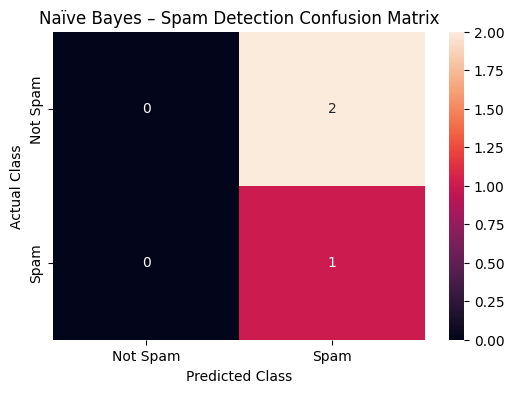

In [ ]:

labels_nb = ["Not Spam", "Spam"]

cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=labels_nb
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    xticklabels=labels_nb,
    yticklabels=labels_nb
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Naïve Bayes – Spam Detection Confusion Matrix")
plt.show()


In [ ]:

new_emails = [
    "Congratulations you have won a free prize",
    "Please submit your project report tomorrow",
    "Claim your cash reward now",
    "The department meeting is at 10 AM"
]

new_email_tfidf = tfidf_spam.transform(new_emails)
new_predictions = nb_model.predict(new_email_tfidf)

new_email_results = pd.DataFrame({
    "New Email": new_emails,
    "Predicted Class": new_predictions
})

new_email_results


,New Email,Predicted Class
0,Congratulations you have won a free prize,Spam
1,Please submit your project report tomorrow,Not Spam
2,Claim your cash reward now,Spam
3,The department meeting is at 10 AM,Not Spam
